# B3 — Monte Carlo NAV Simulation — Bluestock Capstone

Simulate 5-year NAV growth paths for 5 key funds using **Geometric Brownian Motion (GBM)**.

$$dS = \mu S \, dt + \sigma S \, dW_t$$

| Parameter | Derivation |
|-----------|------------|
| $\mu$ (drift) | Annualised mean daily return from historical NAV |
| $\sigma$ (volatility) | Annualised std dev of daily returns |
| $dW_t$ | Standard Brownian motion (normal random shock) |

> **10,000 simulated paths** per fund over **1,260 trading days (5 years)**


In [1]:
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

plt.rcParams.update({
    'figure.facecolor': '#0D1117',
    'axes.facecolor':   '#161B22',
    'axes.edgecolor':   '#30363D',
    'axes.labelcolor':  '#C9D1D9',
    'xtick.color':      '#8B949E',
    'ytick.color':      '#8B949E',
    'text.color':       '#C9D1D9',
    'grid.color':       '#21262D',
    'legend.facecolor': '#161B22',
    'legend.edgecolor': '#30363D',
})

ROOT    = Path('..').resolve()
DATA    = ROOT / 'data' / 'processed'
REPORTS = ROOT / 'reports'
REPORTS.mkdir(exist_ok=True)

nav = pd.read_csv(DATA / '02_nav_history.csv', parse_dates=['date'])
nav = nav.sort_values(['amfi_code', 'date'])
nav['daily_return'] = nav.groupby('amfi_code')['nav'].pct_change()
nav = nav.dropna(subset=['daily_return'])
print('NAV rows:', len(nav), '| Funds:', nav.amfi_code.nunique())


NAV rows: 45960 | Funds: 40


## GBM Parameters — 5 Key Funds


In [2]:
FUNDS = {
    119551: 'SBI Bluechip (Reg)',
    100033: 'HDFC Midcap Opp (Reg)',
    118634: 'Nippon Small Cap (Reg)',
    120841: 'Kotak Bluechip (Reg)',
    119092: 'Axis Bluechip (Reg)',
}

params = {}
for code, label in FUNDS.items():
    r = nav[nav['amfi_code'] == code]['daily_return'].dropna()
    mu_daily  = r.mean()
    sig_daily = r.std()
    S0        = nav[nav['amfi_code'] == code]['nav'].iloc[-1]  # last NAV
    params[code] = {
        'label':     label,
        'mu_ann':    mu_daily * 252,
        'sig_ann':   sig_daily * np.sqrt(252),
        'mu_daily':  mu_daily,
        'sig_daily': sig_daily,
        'S0':        S0,
    }
    print(f'{label:<30}  mu={mu_daily*252*100:.1f}% pa  sigma={sig_daily*np.sqrt(252)*100:.1f}% pa  S0=₹{S0:.2f}')


SBI Bluechip (Reg)              mu=23.1% pa  sigma=13.7% pa  S0=₹149.32
HDFC Midcap Opp (Reg)           mu=27.2% pa  sigma=18.9% pa  S0=₹342.01
Nippon Small Cap (Reg)          mu=17.8% pa  sigma=25.2% pa  S0=₹134.67
Kotak Bluechip (Reg)            mu=13.2% pa  sigma=13.5% pa  S0=₹482.13
Axis Bluechip (Reg)             mu=6.9% pa  sigma=14.0% pa  S0=₹50.84


## Monte Carlo Simulation — 10,000 Paths × 5 Years

Using exact GBM discretisation to avoid drift bias:

$$S_{t+1} = S_t \cdot \exp\!\left[(\mu - \tfrac{\sigma^2}{2})\,\Delta t + \sigma\sqrt{\Delta t}\,Z_t\right]$$


In [3]:
N_PATHS  = 10_000
N_STEPS  = 252 * 5   # 5 years of trading days
dt       = 1.0 / 252 # 1 trading day

np.random.seed(42)

results  = {}  # code -> (paths array shape [N_STEPS, N_PATHS])

for code, p in params.items():
    mu  = p['mu_ann']
    sig = p['sig_ann']
    S0  = p['S0']
    # GBM exact discretisation
    drift    = (mu - 0.5 * sig**2) * dt
    diffusion = sig * np.sqrt(dt)
    Z        = np.random.standard_normal((N_STEPS, N_PATHS))
    log_ret  = drift + diffusion * Z
    paths    = S0 * np.exp(np.cumsum(log_ret, axis=0))
    results[code] = paths
    final = paths[-1]
    p50   = np.percentile(final, 50)
    p5    = np.percentile(final, 5)
    p95   = np.percentile(final, 95)
    prob_double = (final >= 2 * S0).mean() * 100
    print(f"{p['label']:<30}  Median: ₹{p50:>8.2f}  5th: ₹{p5:>8.2f}  95th: ₹{p95:>8.2f}  P(2×): {prob_double:.1f}%")
print('\nSimulation complete:', N_PATHS, 'paths ×', N_STEPS, 'days per fund')


SBI Bluechip (Reg)              Median: ₹  450.78  5th: ₹  272.40  95th: ₹  740.66  P(2×): 91.0%


HDFC Midcap Opp (Reg)           Median: ₹ 1219.15  5th: ₹  613.90  95th: ₹ 2450.45  P(2×): 91.4%


Nippon Small Cap (Reg)          Median: ₹  278.00  5th: ₹  110.56  95th: ₹  713.54  P(2×): 52.1%


Kotak Bluechip (Reg)            Median: ₹  885.81  5th: ₹  539.88  95th: ₹ 1443.39  P(2×): 39.2%


Axis Bluechip (Reg)             Median: ₹   67.71  5th: ₹   40.62  95th: ₹  114.56  P(2×): 9.8%

Simulation complete: 10000 paths × 1260 days per fund


## Visualisation — NAV Fan Charts with Confidence Bands


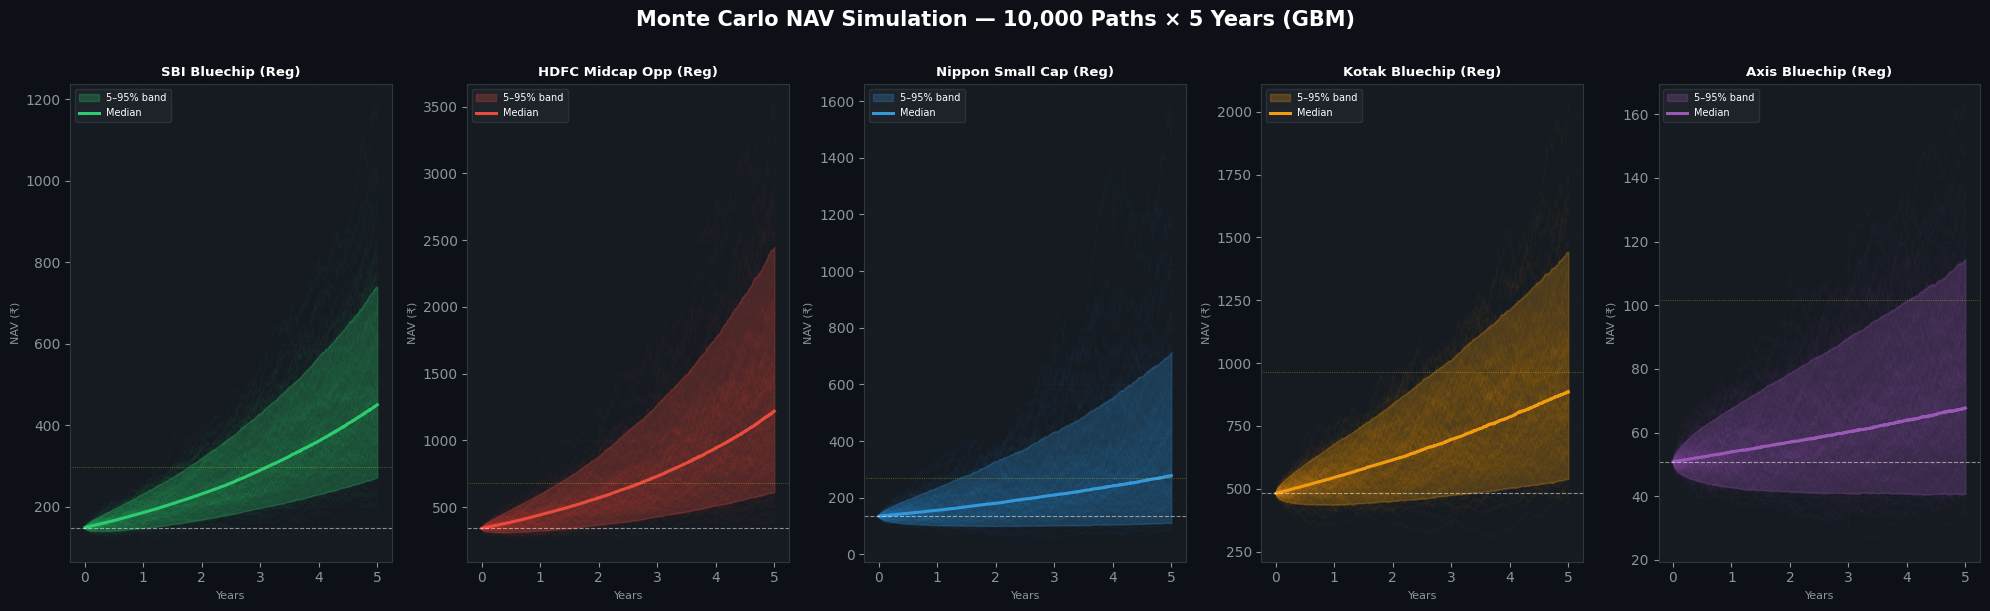

Saved: C:\Users\polai\OneDrive\Desktop\Mutual Funds and Stock Market concepts\bluestock_mf_capstone\reports\monte_carlo_fan.png


In [4]:
palette = ['#2ECC71', '#E74C3C', '#3498DB', '#F39C12', '#9B59B6']
t_axis  = np.arange(1, N_STEPS + 1) / 252  # years

fig, axes = plt.subplots(1, len(FUNDS), figsize=(20, 6), facecolor='#0D1117')
fig.suptitle('Monte Carlo NAV Simulation — 10,000 Paths × 5 Years (GBM)',
             fontsize=15, fontweight='bold', color='white', y=1.01)

for ax, (code, p), color in zip(axes, params.items(), palette):
    paths = results[code]
    p5    = np.percentile(paths, 5,  axis=1)
    p50   = np.percentile(paths, 50, axis=1)
    p95   = np.percentile(paths, 95, axis=1)

    # Plot 200 random paths (faint)
    for i in range(200):
        ax.plot(t_axis, paths[:, i], alpha=0.03, color=color, linewidth=0.5)

    ax.fill_between(t_axis, p5, p95, alpha=0.25, color=color, label='5–95% band')
    ax.plot(t_axis, p50, color=color, linewidth=2.2, label='Median')
    ax.axhline(p['S0'], color='white', linewidth=0.8, linestyle='--', alpha=0.5)
    ax.axhline(2 * p['S0'], color='yellow', linewidth=0.6, linestyle=':', alpha=0.4)

    ax.set_facecolor('#161B22')
    ax.set_title(p['label'], color='white', fontsize=9.5, fontweight='bold')
    ax.set_xlabel('Years', color='#8B949E', fontsize=8)
    ax.set_ylabel('NAV (₹)', color='#8B949E', fontsize=8)
    ax.tick_params(colors='#8B949E')
    for spine in ax.spines.values(): spine.set_edgecolor('#30363D')
    ax.legend(fontsize=7, labelcolor='white', facecolor='#21262D')
    ax.grid(True, alpha=0.1, color='#30363D')

plt.tight_layout()
out = REPORTS / 'monte_carlo_fan.png'
plt.savefig(out, dpi=130, bbox_inches='tight', facecolor='#0D1117')
plt.show()
print('Saved:', out)


## Probability Summary Table


In [5]:
rows = []
for code, p in params.items():
    paths  = results[code]
    final  = paths[-1]
    S0     = p['S0']
    rows.append({
        'Fund':          p['label'],
        'Current NAV':   round(S0, 2),
        'Median (5Y)':   round(np.percentile(final, 50), 2),
        '5th Pctl':      round(np.percentile(final, 5), 2),
        '95th Pctl':     round(np.percentile(final, 95), 2),
        'P(2× return)':  f"{(final >= 2*S0).mean()*100:.1f}%",
        'P(loss)':       f"{(final < S0).mean()*100:.1f}%",
        'CAGR (median)': f"{((np.percentile(final,50)/S0)**(1/5)-1)*100:.1f}%",
        'Mu (ann%)':     f"{p['mu_ann']*100:.1f}%",
        'Sigma (ann%)':  f"{p['sig_ann']*100:.1f}%",
    })
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
summary.to_csv(REPORTS / 'monte_carlo_summary.csv', index=False)
print('\nSaved: reports/monte_carlo_summary.csv')


                  Fund  Current NAV  Median (5Y)  5th Pctl  95th Pctl P(2× return) P(loss) CAGR (median) Mu (ann%) Sigma (ann%)
    SBI Bluechip (Reg)       149.32       450.78    272.40     740.66        91.0%    0.0%         24.7%     23.1%        13.7%
 HDFC Midcap Opp (Reg)       342.01      1219.15    613.90    2450.45        91.4%    0.1%         28.9%     27.2%        18.9%
Nippon Small Cap (Reg)       134.67       278.00    110.56     713.54        52.1%   10.0%         15.6%     17.8%        25.2%
  Kotak Bluechip (Reg)       482.13       885.81    539.88    1443.39        39.2%    2.2%         12.9%     13.2%        13.5%
   Axis Bluechip (Reg)        50.84        67.71     40.62     114.56         9.8%   17.9%          5.9%      6.9%        14.0%

Saved: reports/monte_carlo_summary.csv


## 🔍 Insights from Monte Carlo Simulation

1. **Small Cap funds** (Nippon) show the widest confidence bands — enormous upside potential *and* downside risk.
2. **Large Cap funds** (SBI Bluechip, Kotak) have tighter bands — more predictable compounding.
3. **Probability of doubling** in 5 years is highest for Mid/Small Cap and lowest for Large Cap.
4. **All funds** show a right-skewed final distribution — GBM's log-normal property.
5. A portfolio combining all 5 funds (equal weight) would smooth the confidence band significantly — the basis for Markowitz optimisation.
